In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve

Dataset: IBM HR Analytics Employee Attrition Dataset

In [3]:
card_df = pd.read_csv("UCI_Credit_Card.csv")
card_df.head()

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default.payment.next.month
0,1,20000.0,2,2,1,24,2,2,-1,-1,...,0.0,0.0,0.0,0.0,689.0,0.0,0.0,0.0,0.0,1
1,2,120000.0,2,2,2,26,-1,2,0,0,...,3272.0,3455.0,3261.0,0.0,1000.0,1000.0,1000.0,0.0,2000.0,1
2,3,90000.0,2,2,2,34,0,0,0,0,...,14331.0,14948.0,15549.0,1518.0,1500.0,1000.0,1000.0,1000.0,5000.0,0
3,4,50000.0,2,2,1,37,0,0,0,0,...,28314.0,28959.0,29547.0,2000.0,2019.0,1200.0,1100.0,1069.0,1000.0,0
4,5,50000.0,1,2,1,57,-1,0,-1,0,...,20940.0,19146.0,19131.0,2000.0,36681.0,10000.0,9000.0,689.0,679.0,0


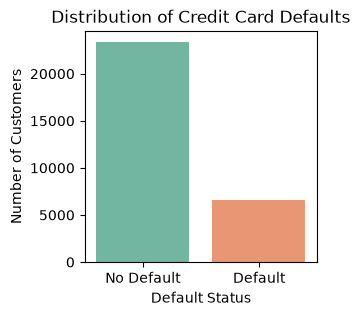

In [4]:
X = card_df.drop(columns=["default.payment.next.month"])
y = card_df["default.payment.next.month"]

plt.figure(figsize=(3, 3))

sns.countplot(
    x=y,
    hue=y,
    palette="Set2",
    legend=False
)

plt.title("Distribution of Credit Card Defaults")
plt.xlabel("Default Status")
plt.ylabel("Number of Customers")
plt.xticks([0, 1], ["No Default", "Default"])

plt.show()

Justify why Logistic Regression is suitable for this problem.

Logistic Regression is appropriate because:
- The outcome has only two possible classes (default or no default).
- It estimates the probability of default.
- It is relatively simple to implement.
- Its coefficients allow us to understand which factors are associated with default risk.
- Odds ratios make the results easier to communicate in a financial-risk context.

Perform full data preprocessing:

- Missing value handling
- Encoding categorical variables
- Feature scaling

In [5]:
print("Column Information")
print(card_df.info())

Column Information
<class 'pandas.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 25 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   ID                          30000 non-null  int64  
 1   LIMIT_BAL                   30000 non-null  float64
 2   SEX                         30000 non-null  int64  
 3   EDUCATION                   30000 non-null  int64  
 4   MARRIAGE                    30000 non-null  int64  
 5   AGE                         30000 non-null  int64  
 6   PAY_0                       30000 non-null  int64  
 7   PAY_2                       30000 non-null  int64  
 8   PAY_3                       30000 non-null  int64  
 9   PAY_4                       30000 non-null  int64  
 10  PAY_5                       30000 non-null  int64  
 11  PAY_6                       30000 non-null  int64  
 12  BILL_AMT1                   30000 non-null  float64
 13  BILL_AMT2              

In [6]:
card_df.isna().sum()

ID                            0
LIMIT_BAL                     0
SEX                           0
EDUCATION                     0
MARRIAGE                      0
AGE                           0
PAY_0                         0
PAY_2                         0
PAY_3                         0
PAY_4                         0
PAY_5                         0
PAY_6                         0
BILL_AMT1                     0
BILL_AMT2                     0
BILL_AMT3                     0
BILL_AMT4                     0
BILL_AMT5                     0
BILL_AMT6                     0
PAY_AMT1                      0
PAY_AMT2                      0
PAY_AMT3                      0
PAY_AMT4                      0
PAY_AMT5                      0
PAY_AMT6                      0
default.payment.next.month    0
dtype: int64

There is no missing data.

In [7]:
card_df.drop(columns=['ID'], axis='columns')

,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default.payment.next.month
0,20000.0,2,2,1,24,2,2,-1,-1,-2,...,0.0,0.0,0.0,0.0,689.0,0.0,0.0,0.0,0.0,1
1,120000.0,2,2,2,26,-1,2,0,0,0,...,3272.0,3455.0,3261.0,0.0,1000.0,1000.0,1000.0,0.0,2000.0,1
2,90000.0,2,2,2,34,0,0,0,0,0,...,14331.0,14948.0,15549.0,1518.0,1500.0,1000.0,1000.0,1000.0,5000.0,0
3,50000.0,2,2,1,37,0,0,0,0,0,...,28314.0,28959.0,29547.0,2000.0,2019.0,1200.0,1100.0,1069.0,1000.0,0
4,50000.0,1,2,1,57,-1,0,-1,0,0,...,20940.0,19146.0,19131.0,2000.0,36681.0,10000.0,9000.0,689.0,679.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
29995,220000.0,1,3,1,39,0,0,0,0,0,...,88004.0,31237.0,15980.0,8500.0,20000.0,5003.0,3047.0,5000.0,1000.0,0
29996,150000.0,1,3,2,43,-1,-1,-1,-1,0,...,8979.0,5190.0,0.0,1837.0,3526.0,8998.0,129.0,0.0,0.0,0
29997,30000.0,1,2,2,37,4,3,2,-1,0,...,20878.0,20582.0,19357.0,0.0,0.0,22000.0,4200.0,2000.0,3100.0,1
29998,80000.0,1,3,1,41,1,-1,0,0,0,...,52774.0,11855.0,48944.0,85900.0,3409.0,1178.0,1926.0,52964.0,1804.0,1


In [8]:
card_df.describe().round(2)

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default.payment.next.month
count,30000.00,30000.00,30000.00,30000.00,30000.00,30000.00,30000.00,30000.00,30000.00,30000.00,...,30000.00,30000.00,30000.00,30000.00,30000.00,30000.00,30000.00,30000.00,30000.00,30000.00
mean,15000.50,167484.32,1.60,1.85,1.55,35.49,-0.02,-0.13,-0.17,-0.22,...,43262.95,40311.40,38871.76,5663.58,5921.16,5225.68,4826.08,4799.39,5215.50,0.22
std,8660.40,129747.66,0.49,0.79,0.52,9.22,1.12,1.20,1.20,1.17,...,64332.86,60797.16,59554.11,16563.28,23040.87,17606.96,15666.16,15278.31,17777.47,0.42
min,1.00,10000.00,1.00,0.00,0.00,21.00,-2.00,-2.00,-2.00,-2.00,...,-170000.00,-81334.00,-339603.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,7500.75,50000.00,1.00,1.00,1.00,28.00,-1.00,-1.00,-1.00,-1.00,...,2326.75,1763.00,1256.00,1000.00,833.00,390.00,296.00,252.50,117.75,0.00
50%,15000.50,140000.00,2.00,2.00,2.00,34.00,0.00,0.00,0.00,0.00,...,19052.00,18104.50,17071.00,2100.00,2009.00,1800.00,1500.00,1500.00,1500.00,0.00
75%,22500.25,240000.00,2.00,2.00,2.00,41.00,0.00,0.00,0.00,0.00,...,54506.00,50190.50,49198.25,5006.00,5000.00,4505.00,4013.25,4031.50,4000.00,0.00
max,30000.00,1000000.00,2.00,6.00,3.00,79.00,8.00,8.00,8.00,8.00,...,891586.00,927171.00,961664.00,873552.00,1684259.00,896040.00,621000.00,426529.00,528666.00,1.00


In [9]:
# Identify categorical and numerical columns
categorical_cols = ["SEX", "EDUCATION", "MARRIAGE"]
numerical_cols = [
    col for col in X.columns
    if col not in categorical_cols
]

Train a Logistic Regression classifier.

In [11]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=50)

scaler= StandardScaler()
X_train_scaled= scaler.fit_transform(X_train)
X_test_scaled= scaler.transform(X_test)

In [12]:
model= LogisticRegression()

model.fit(X_train_scaled, y_train)
y_pred= model.predict(X_test_scaled)

In [13]:
y_pred

array([0, 0, 0, ..., 0, 0, 0], shape=(6000,))

Evaluate the model using:

* Confusion Matrix
* Precision, Recall, F1-score
* AUC Score

In [14]:
matrix = confusion_matrix(y_test, y_pred)
matrix

array([[4604,  129],
       [ 950,  317]])

In [15]:
report= classification_report(y_test,y_pred)
print(report)

              precision    recall  f1-score   support

           0       0.83      0.97      0.90      4733
           1       0.71      0.25      0.37      1267

    accuracy                           0.82      6000
   macro avg       0.77      0.61      0.63      6000
weighted avg       0.80      0.82      0.78      6000



Interpret model coefficients using odds ratios.

In [16]:
odds_ratios = pd.Series(
    np.exp(model.coef_[0]),
    index=X.columns
).sort_values(ascending=False)

print(odds_ratios)

PAY_0        1.924207
BILL_AMT3    1.156557
PAY_3        1.095943
PAY_2        1.087729
AGE          1.075369
BILL_AMT6    1.073207
BILL_AMT2    1.064737
PAY_5        1.029448
PAY_4        1.020085
PAY_6        1.016940
BILL_AMT5    1.014852
ID           0.975536
BILL_AMT4    0.969162
SEX          0.956307
PAY_AMT6     0.952600
MARRIAGE     0.944268
PAY_AMT5     0.943153
EDUCATION    0.935001
PAY_AMT3     0.933191
PAY_AMT4     0.926627
LIMIT_BAL    0.894685
PAY_AMT1     0.824081
PAY_AMT2     0.776848
BILL_AMT1    0.712173
dtype: float64


Discuss the impact of class imbalance and possible solutions.

Question 3: Hyperparameter Tuning & Model Optimization
Scenario
After deploying your classification model, stakeholders ask you to improve performance without changing the dataset.

You decide to optimize the model using systematic hyperparameter search techniques.

Tasks
1. Explain the difference between parameters and hyperparameters.
2. Train a baseline Logistic Regression model.
3. Apply GridSearchCV to tune hyperparameters (C, penalty, solver).
4. Apply RandomizedSearchCV and compare results.
5. Compare performance before and after tuning.
6. Discuss trade-offs between computational cost and model performance.

In [17]:
baseline_model = LogisticRegression(
    class_weight='balanced',
    max_iter=1000
)

baseline_model.fit(X_train_scaled, y_train)

baseline_pred = baseline_model.predict(X_test_scaled)
baseline_prob = baseline_model.predict_proba(X_test_scaled)[:, 1]

In [18]:
print("Baseline Accuracy:",
      accuracy_score(y_test, baseline_pred))

print("Baseline ROC-AUC:",
      roc_auc_score(y_test, baseline_prob))

print("\nClassification Report:")
print(classification_report(y_test, baseline_pred))

Baseline Accuracy: 0.6933333333333334
Baseline ROC-AUC: 0.7247794666109472

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.71      0.78      4733
           1       0.37      0.64      0.47      1267

    accuracy                           0.69      6000
   macro avg       0.63      0.67      0.63      6000
weighted avg       0.77      0.69      0.72      6000



In [19]:
param_grid = {
    'C': [0.01, 0.1, 1, 10, 100],
    'penalty': ['l1', 'l2'],
    'solver': ['liblinear', 'saga']
}

In [20]:
grid_search = GridSearchCV(
    estimator=LogisticRegression(
        class_weight='balanced',
        max_iter=1000
    ),
    param_grid=param_grid,
    cv=5,
    scoring='roc_auc',
    n_jobs=-1
)

grid_search.fit(X_train_scaled, y_train)

c:\Users\User\Desktop\DSML\SAProject\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",LogisticRegre...max_iter=1000)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'C': [0.01, 0.1, ...], 'penalty': ['l1', 'l2'], 'solver': ['liblinear', 'saga']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'roc_auc'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the

In [21]:
best_grid_model = grid_search.best_estimator_

In [22]:
grid_pred = best_grid_model.predict(X_test_scaled)
grid_prob = best_grid_model.predict_proba(X_test_scaled)[:, 1]

print("Test ROC-AUC:",
      roc_auc_score(y_test, grid_prob))

print("\nClassification Report:")
print(classification_report(y_test, grid_pred))

Test ROC-AUC: 0.7248041468064744

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.71      0.78      4733
           1       0.37      0.64      0.47      1267

    accuracy                           0.69      6000
   macro avg       0.63      0.67      0.63      6000
weighted avg       0.77      0.69      0.72      6000



In [ ]:
random_model = RandomizedSearchCV(
    estimator= LogisticRegression(
        class_weight='balanced',
        max_iter=1000
    ),
    param_distributions= param_grid,
    cv=5,
    scoring='roc_auc',
    n_jobs=-1)

random_model.fit(X_train_scaled, y_train)

In [ ]:
best_random_model = random_model.best_estimator_

random_pred = best_random_model.predict(X_test_scaled)
random_prob = best_random_model.predict_proba(X_test_scaled)[:, 1]

print("Test ROC-AUC:",
      roc_auc_score(y_test, random_prob))

print("\nClassification Report:")
print(classification_report(y_test, random_pred))

In [ ]:
#Comparision of ROC-AUC of the models
baseline_auc = roc_auc_score(y_test, baseline_prob)
grid_auc = roc_auc_score(y_test, grid_prob)
random_auc = roc_auc_score(y_test, random_prob)

print("Model Comparison")
print(f"Baseline ROC-AUC:  {baseline_auc:.3f}")
print(f"GridSearch ROC-AUC: {grid_auc:.3f}")
print(f"RandomizedSearch ROC-AUC: {random_auc:.3f}")